K-Means Clustering

K-Means termasuk unsupervised learning. Algoritma ini mengelompokkan data berdasarkan kemiripan fitur tanpa menggunakan label target saat proses pembentukan cluster.

Persiapan Library dan Dataset

Dataset WineQT berisi karakteristik kimia wine. Kolom `quality` tidak digunakan untuk membentuk cluster; kolom tersebut hanya dapat dibandingkan setelah clustering untuk membantu interpretasi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

data = pd.read_csv("data/WineQT.csv")

print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Menyiapkan Fitur

Kolom `Id` hanya merupakan identitas baris, sedangkan `quality` adalah label kualitas. Keduanya dikeluarkan dari fitur clustering. StandardScaler digunakan karena skala antarfitur kimia berbeda.

In [2]:
X = data.drop(columns=["Id", "quality"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])

Jumlah fitur: 11
Jumlah data: 1143


Menentukan Jumlah Cluster dengan Elbow Method

*Inertia* mengukur jumlah kuadrat jarak setiap data ke pusat cluster-nya. Nilai inertia akan menurun ketika jumlah cluster bertambah. Titik siku (elbow) dapat menjadi petunjuk jumlah cluster yang sesuai.

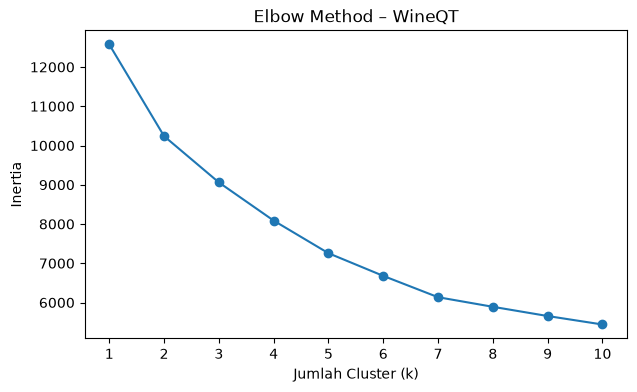

In [3]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method – WineQT")
plt.xticks(list(k_values))
plt.show()

Membuat Model K-Means

Sebagai contoh awal, model dibuat dengan tiga cluster. `random_state` menjaga hasil agar konsisten, sedangkan `n_init` menjalankan inisialisasi beberapa kali untuk mencari hasil yang lebih baik.

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

data_clustered = data.copy()
data_clustered["cluster"] = clusters

display(data_clustered[["quality", "cluster"]].head())
print("Jumlah data pada setiap cluster:")
display(data_clustered["cluster"].value_counts().sort_index())

,quality,cluster
0,5,0
1,5,1
2,5,0
3,6,2
4,5,0


Jumlah data pada setiap cluster:


cluster
0    523
1    271
2    349
Name: count, dtype: int64

Visualisasi Cluster

Karena data memiliki banyak fitur, PCA digunakan untuk mereduksi fitur menjadi dua komponen agar hasil pengelompokan dapat divisualisasikan. PCA hanya digunakan untuk visualisasi; clustering tetap dilakukan menggunakan seluruh fitur yang telah distandardisasi.

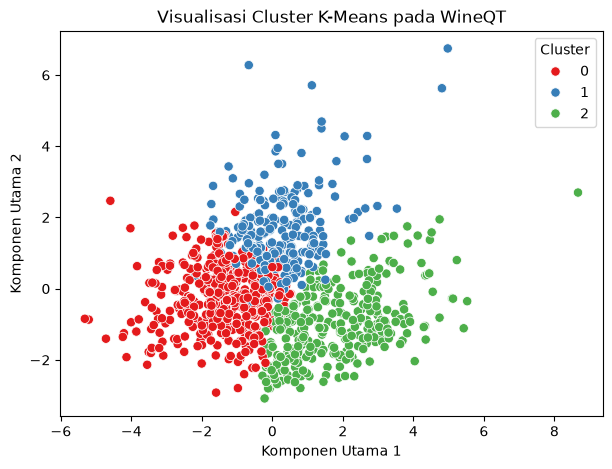

In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=clusters, palette="Set1", s=45
)
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.title("Visualisasi Cluster K-Means pada WineQT")
plt.legend(title="Cluster")
plt.show()

Memahami Hasil Cluster

Tabel berikut menunjukkan rata-rata fitur pada setiap cluster. Gunakan hasil ini untuk melihat karakteristik kimia yang membedakan kelompok wine.

In [6]:
cluster_summary = data_clustered.groupby("cluster")[X.columns].mean().round(2)
display(cluster_summary)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
cluster,,,,,,,,,,,
0,7.19,0.61,0.12,2.19,0.08,13.39,34.40,1.0,3.40,0.61,10.53
1,8.16,0.55,0.28,3.02,0.09,26.27,88.57,1.0,3.28,0.62,9.86
2,10.11,0.41,0.48,2.67,0.10,10.68,30.05,1.0,3.19,0.75,10.76


Kolom `quality` dapat diperiksa setelah clustering untuk memahami distribusi kualitas pada masing-masing kelompok. Nilai ini **tidak** digunakan oleh K-Means saat membentuk cluster.

In [7]:
display(
    data_clustered.groupby("cluster")["quality"]
    .agg(["count", "mean", "median"])
    .round(2)
)

,count,mean,median
cluster,,,
0,523,5.59,6.0
1,271,5.35,5.0
2,349,6.00,6.0


Evaluasi Sederhana

Silhouette Score memberikan gambaran seberapa baik data berada di dalam clusternya dibandingkan dengan cluster lain. Nilainya berkisar dari -1 hingga 1; semakin tinggi biasanya menunjukkan pemisahan cluster yang lebih baik.

In [8]:
score = silhouette_score(X_scaled, clusters)
print(f"Silhouette Score: {score:.3f}")

Silhouette Score: 0.183


Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.